Import LIbraries

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings, re, string, time
warnings.filterwarnings('ignore')

#nlp
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from wordcloud  import WordCloud
from nltk import ngrams
from collections import Counter


for pkg in ['stopwords', 'wordnet', 'punkt', 'punkt_tab']:
  nltk.download(pkg)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [2]:
# load dataset
df = pd.read_csv('/content/HumanVsAI-2026.csv')
df.head()

,id,text,label,source,complexity_score,grammar_errors_count,sentence_length
0,1,i think technology is kinda har but i'l try anywa,Human,research,0.49,2,10
1,2,kal ma machine learning krna bhool gaya lol,Human,essay,0.43,3,8
2,3,Deep learning techniques have improved technol...,AI,blog,0.64,1,7
3,4,Machine learning models are widely used in stu...,AI,blog,0.71,1,11
4,5,Artificial intelligence is transforming machin...,AI,tweet,0.85,0,10


Data Exploration

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    5000 non-null   int64  
 1   text                  5000 non-null   object 
 2   label                 5000 non-null   object 
 3   source                5000 non-null   object 
 4   complexity_score      5000 non-null   float64
 5   grammar_errors_count  5000 non-null   int64  
 6   sentence_length       5000 non-null   int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 273.6+ KB


In [4]:
df.describe()

,id,complexity_score,grammar_errors_count,sentence_length
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,2500.500000,0.550020,2.472600,8.813800
std,1443.520003,0.127771,1.703711,1.505185
min,1.000000,0.280000,0.000000,7.000000
25%,1250.750000,0.450000,1.000000,7.000000
50%,2500.500000,0.540000,2.000000,9.000000
75%,3750.250000,0.640000,4.000000,10.000000
max,5000.000000,0.860000,5.000000,13.000000


In [5]:
df.shape[1]

7

In [6]:
print(f'Total Human samples: {(df.label=='Human').sum()}')
print(f'Total AI samples: {(df.label=='AI').sum()}')
print(f'Total Missing samples: {df.isnull().sum().sum()}')
print(f'Total Duplicatge samples: {df.duplicated().sum()}')

Total Human samples: 2462
Total AI samples: 2538
Total Missing samples: 0
Total Duplicatge samples: 0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    5000 non-null   int64  
 1   text                  5000 non-null   object 
 2   label                 5000 non-null   object 
 3   source                5000 non-null   object 
 4   complexity_score      5000 non-null   float64
 5   grammar_errors_count  5000 non-null   int64  
 6   sentence_length       5000 non-null   int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 273.6+ KB


NLP Clearning

In [10]:
lematizer = WordNetLemmatizer()
top_words = set(stopwords.words('english'))
def textPreprocessing(text):

  text = text.lower()
  text = re.sub(r'http\S+|www\.\S+', '', text) # Remove URLs
  text = re.sub(r'<.*?>', '', text) # Remove HTML tags
  text = re.sub(r'\d+', '', text) # Remove numbers
  text = re.sub(r'[%s]' % re.escape(string.punctuation), '', text) # Remove punctuation
  text = re.sub(r'[^a-zA-Z\s]', '', text) # Remove special characters

  tokens = word_tokenize(text)
  tokens = [t for t in tokens if t not in stop_words and len(t)>2]

  #lemmatize
  tokens = [lematizer.lemmatize(t) for t in tokens]
  return ' '.join(tokens)

In [12]:
stop_words = top_words
df['clean_text'] = df['text'].apply(textPreprocessing)

In [13]:
df['text'].iloc[23]

'Generative AI can create gym using decision making.'

In [14]:
df['clean_text'].iloc[23]

'generative create gym using decision making'

In [ ]:
df.head()

In [15]:
# x = "Mai NLP sikh raha hu aur sunday ko project bana raha hu"
# np.mean([len(w) for w in str(x).split()])

In [16]:
# df['text'].apply(len)
df['text_length'] = df['text'].apply(len)
df['avg_word_len'] = df['text'].apply(
    lambda x: np.mean([len(w) for w in str(x).split()]) if str(x).split() else 0)

df['clean_sentence_length'] = df['clean_text'].apply(lambda x: len(str(x).split()))


In [17]:
df.head()

,id,text,label,source,complexity_score,grammar_errors_count,sentence_length,clean_text,text_length,avg_word_len,clean_sentence_length
0,1,i think technology is kinda har but i'l try anywa,Human,research,0.49,2,10,think technology kinda har try anywa,49,4.000000,6
1,2,kal ma machine learning krna bhool gaya lol,Human,essay,0.43,3,8,kal machine learning krna bhool gaya lol,43,4.500000,7
2,3,Deep learning techniques have improved technol...,AI,blog,0.64,1,7,deep learning technique improved technology si...,64,8.285714,6
3,4,Machine learning models are widely used in stu...,AI,blog,0.71,1,11,machine learning model widely used studying be...,71,5.545455,8
4,5,Artificial intelligence is transforming machin...,AI,tweet,0.85,0,10,artificial intelligence transforming machine l...,85,7.600000,8



EDA

In [18]:
plt.rcParams.update({'figure.dpi': 130, 'font.family': 'DejaVu Sans'})
PALETTE = ['#99331F', '#1F9966']

Text(0, 0.5, 'Count')

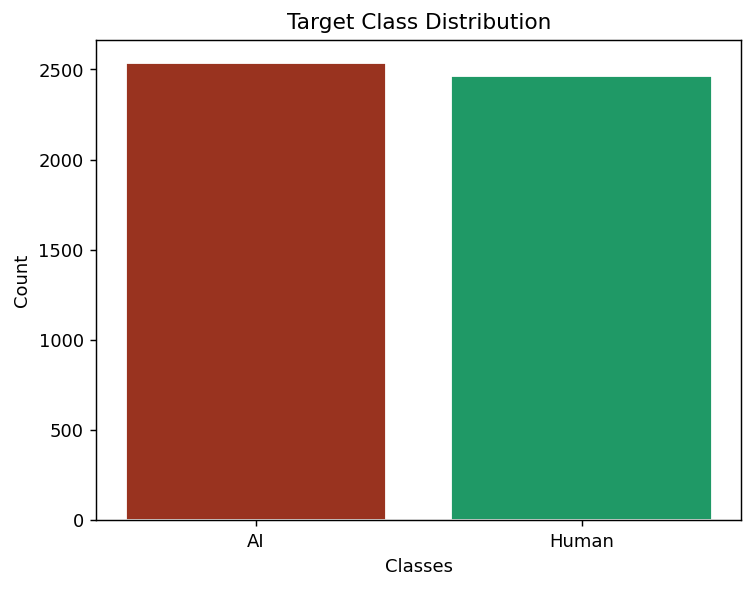

In [19]:
counts = df['label'].value_counts()
plt.bar(counts.index,
        counts.values,
        color = PALETTE,
        edgecolor='white')
plt.title('Target Class Distribution')
plt.xlabel('Classes')
plt.ylabel('Count')

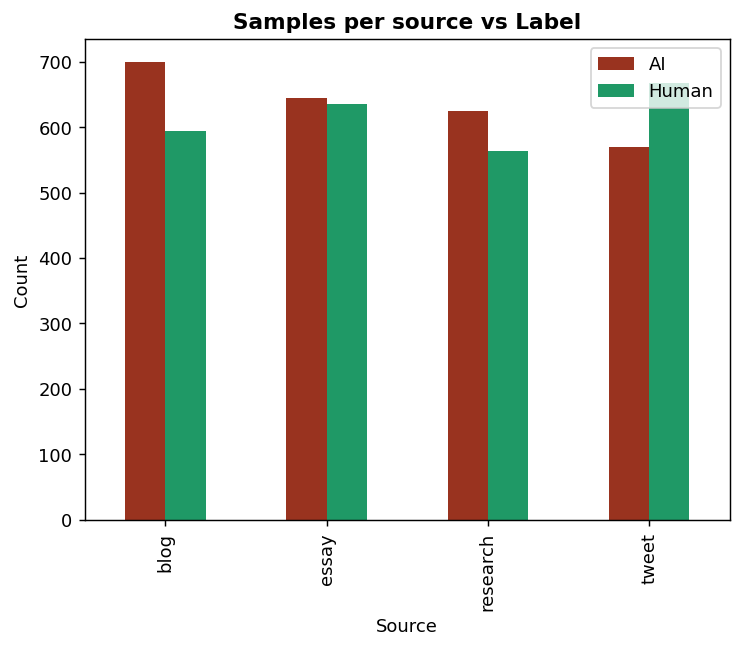

In [20]:
src_label = df.groupby(['source', 'label']).size().unstack(fill_value=0)
src_label.plot(kind='bar',
               color=PALETTE)

plt.title('Samples per source vs Label', fontweight ='bold')
plt.xlabel('Source')
plt.ylabel('Count')
plt.legend()

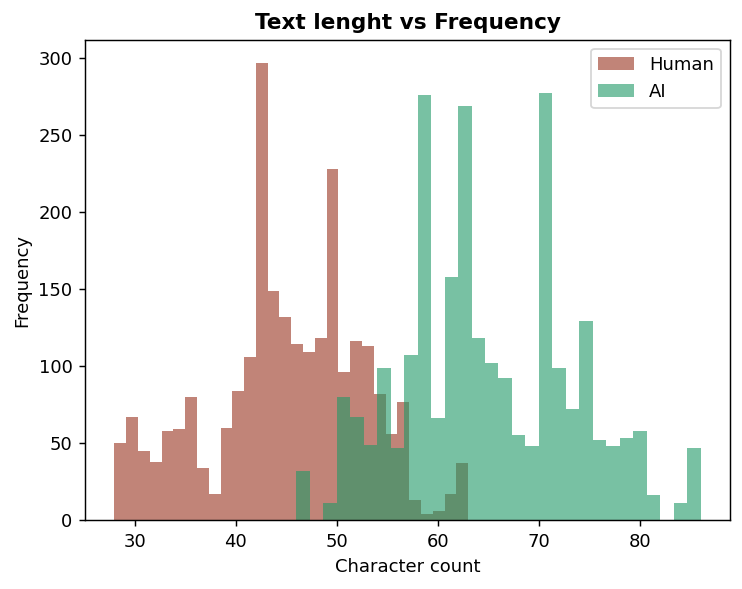

In [21]:

for label, col in zip(['Human', 'AI'], PALETTE):
  subset = df[df['label']==label]['text_length']
  plt.hist(subset, bins=30,
           alpha=0.6,
           color = col,
           label= label)
plt.title('Text lenght vs Frequency', fontweight ='bold')
plt.xlabel('Character count')
plt.ylabel('Frequency')
plt.legend()

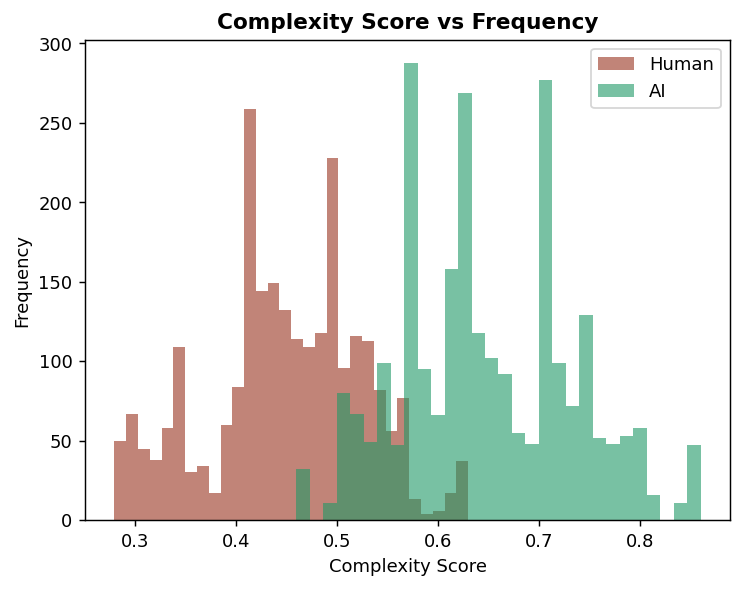

In [22]:
for label, col in zip(['Human', 'AI'], PALETTE):
  subset = df[df['label']==label]['complexity_score']
  plt.hist(subset, bins=30,
           alpha=0.6,
           color = col,
           label= label)
plt.title('Complexity Score vs Frequency', fontweight ='bold')
plt.xlabel('Complexity Score')
plt.ylabel('Frequency')
plt.legend()

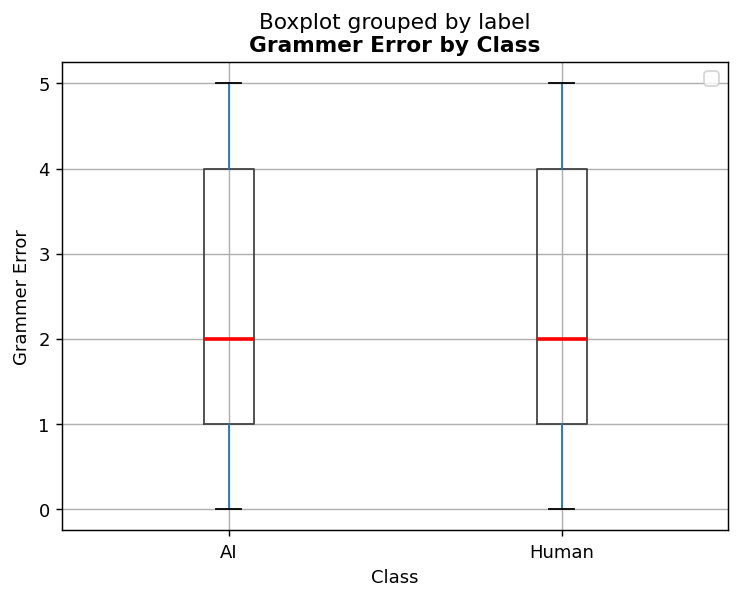

In [23]:
df.boxplot(column = 'grammar_errors_count',
           by = 'label',
           boxprops = dict(color='#444'),
           medianprops = dict(color='red',linewidth=2))

plt.title('Grammer Error by Class', fontweight ='bold')
plt.xlabel('Class')
plt.ylabel('Grammer Error')
plt.legend()

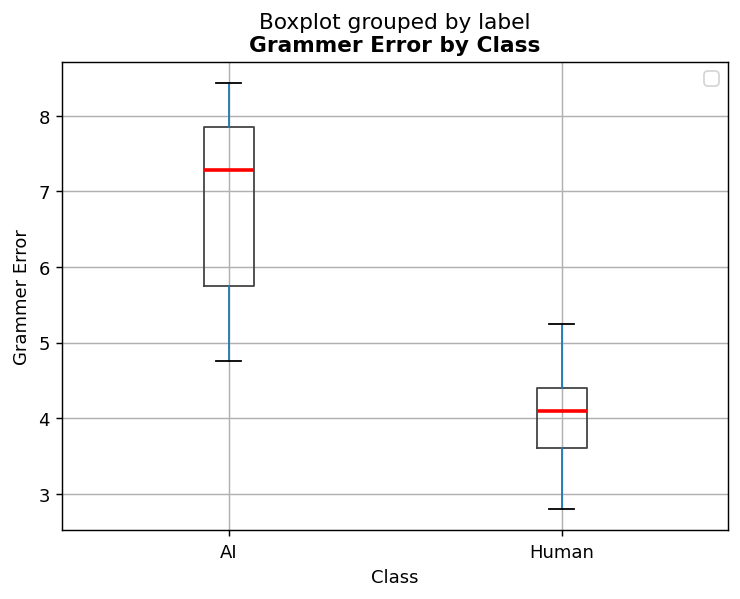

In [24]:
df.boxplot(column = 'avg_word_len',
           by = 'label',
           boxprops = dict(color='#444'),
           medianprops = dict(color='red',linewidth=2))

plt.title('Grammer Error by Class', fontweight ='bold')
plt.xlabel('Class')
plt.ylabel('Grammer Error')
plt.legend()



Corelation Heatmap

In [25]:
df.columns

Index(['id', 'text', 'label', 'source', 'complexity_score',
       'grammar_errors_count', 'sentence_length', 'clean_text', 'text_length',
       'avg_word_len', 'clean_sentence_length'],
      dtype='object')

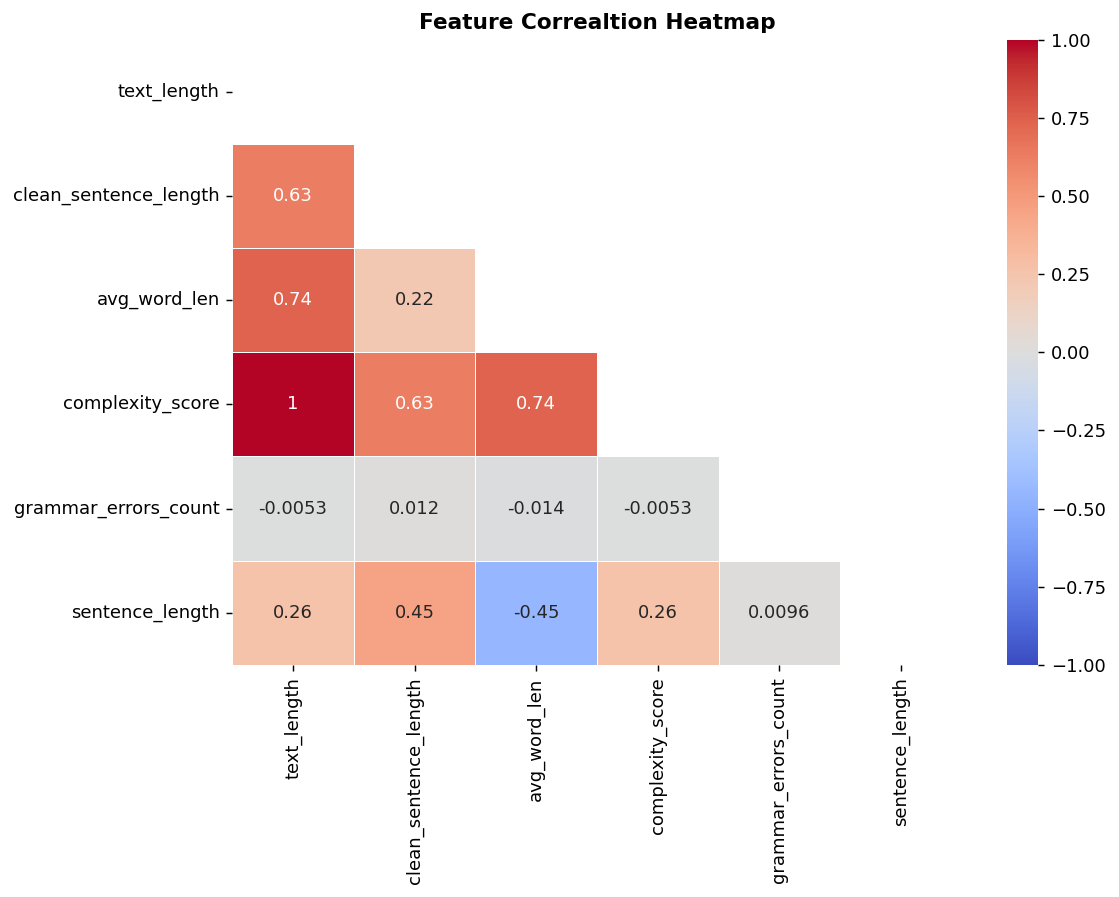

In [26]:
num_cols = ['text_length','clean_sentence_length','avg_word_len','complexity_score',
            'grammar_errors_count','sentence_length']

fig, ax = plt.subplots(figsize=(9,7))

corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr,
            annot=True,
            cmap='coolwarm',
            ax=ax,
            mask= mask,
            linewidth=0.5, vmin=-1, vmax=1)

ax.set_title('Feature Correaltion Heatmap', fontweight='bold')

plt.tight_layout()
plt.show()

N Gram Analysis

In [27]:
def getTopNgrams(corpus, n, top_k):
  words = ' '.join(corpus).split()
  return Counter(ngrams(words,n)).most_common(top_k)

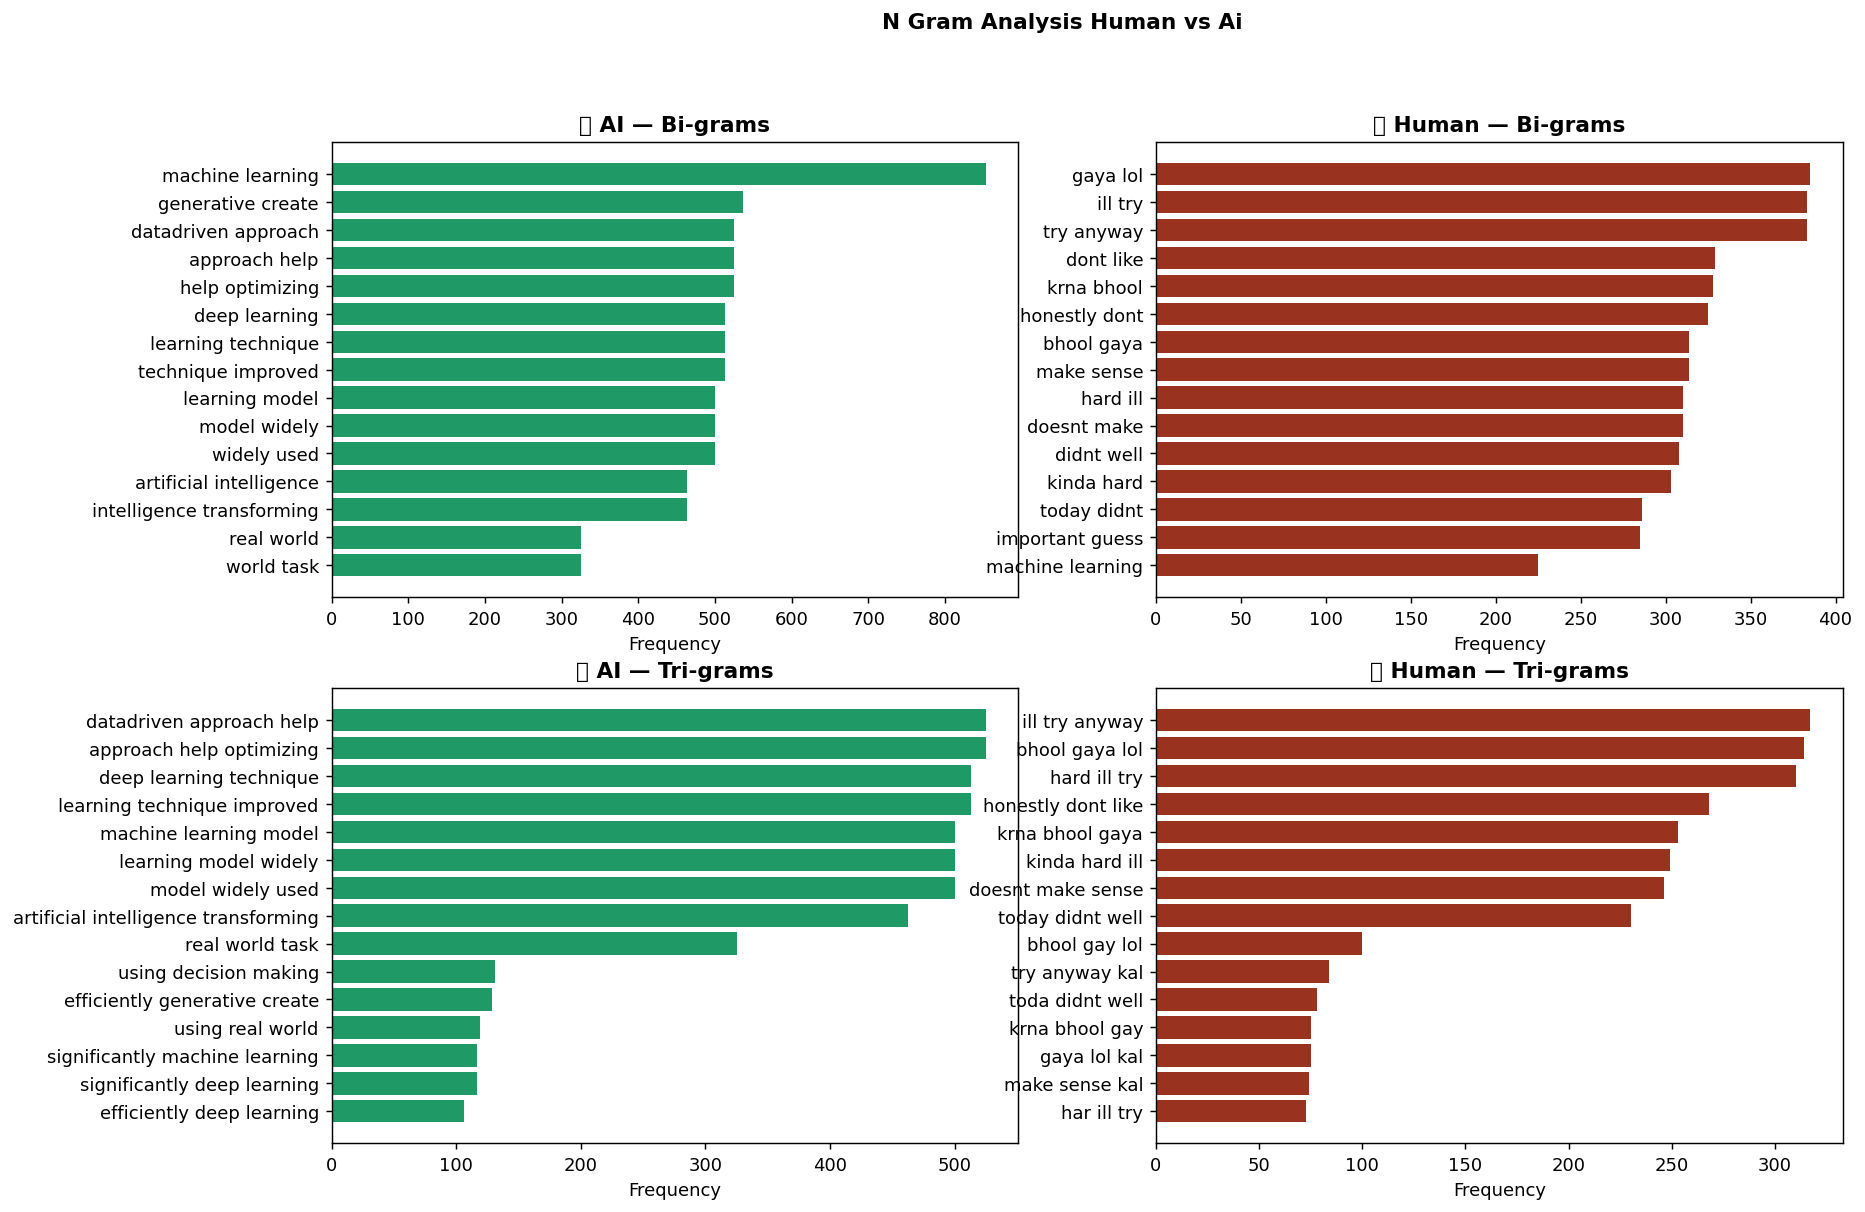

In [28]:
ai_corpus = df[df['label']=='AI']['clean_text'].tolist()
human_corpus = df[df['label']=='Human']['clean_text'].tolist()

fig,axes = plt.subplots(2,2, figsize=(15,10))

fig.suptitle('N Gram Analysis Human vs Ai', fontweight = 'bold')

configs = [(ai_corpus, 2, '🤖 AI — Bi-grams', PALETTE[1]),
           (human_corpus, 2, '🧠 Human — Bi-grams', PALETTE[0]),
           (ai_corpus, 3, '🤖 AI — Tri-grams', PALETTE[1]),
           (human_corpus, 3, '🧠 Human — Tri-grams', PALETTE[0])]


for ax, (corpus, n, title, color)in zip(axes.flatten(), configs):
  top = getTopNgrams(corpus, n=n, top_k=15)
  labels = [' '.join(x) for x, _ in top]
  values = [v for _, v in top]
  ax.barh(labels[::-1], values[::-1], color=color)
  ax.set_title(title, fontweight='bold')
  ax.set_xlabel('Frequency')

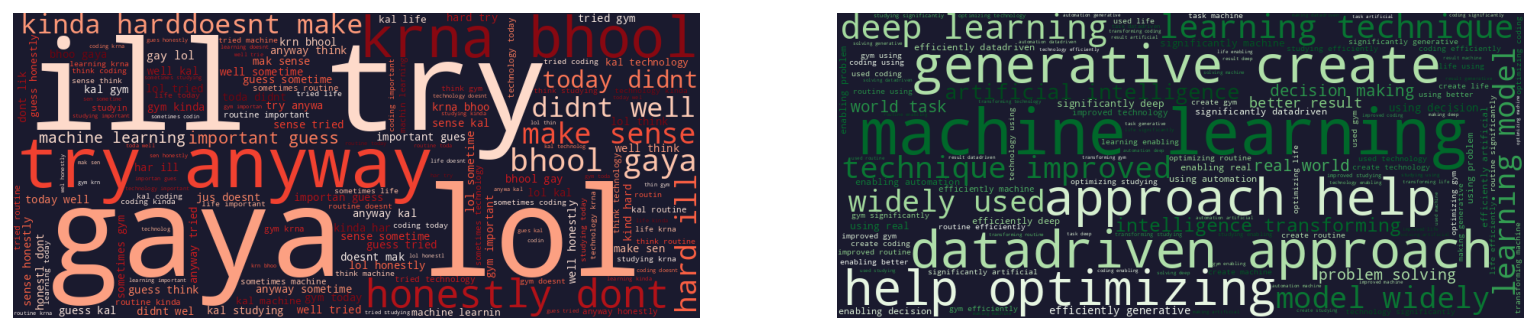

In [29]:

fig,axes = plt.subplots(1,2, figsize=(15,10))

for ax, (lbl, col, bg) in zip(axes,
 [('Human', 'Reds', '#89991F'),
  ('AI', 'Greens', '#89991F' )]):
  corpus = ' '.join(df[df['label']==lbl]['clean_text'].tolist())

  wc = WordCloud(
      width=900, height = 400,
      background_color='#1a1a2e',
      colormap=col,
      max_words = 150,
      contour_color='white',
      contour_width=1
  ).generate(corpus)
  ax.imshow(wc)
  ax.axis('off')